## 1. Import & Install Packages

In [ ]:
# %%capture
!pip install google-colab-selenium[undetected]
!pip install torchvision
!pip install pycocotools

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 11.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.4/65.4 kB 3.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 467.7/467.7 kB 23.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.2/130.2 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.3/58.3 kB 4.9 MB/s eta 0:00:00
  Created wheel for undetected-chromedriver: filename=undetected_chromedriver-3.5.5-py3-none-any.whl size=47048 sha256=d9781a1bb7c03ff3e0710e5d5823cb2e775e26af6354a8f7507f61cc3470fe16
  Stored in directory: /root/.cache/pip/wheels/cf/a1/db/e1275b6f7259aacd6b045f8bfcb1fcbc93827a3916ba55d5b7
Successfully built undetected-chromedriver
  Using cached nvidia_cuda_nvrtc_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (23.7 MB)
  Using cached nvidia_cuda_runtime_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (823 kB)
  Using cached nvidia_cuda_cupti_cu12-12.1.1

In [ ]:
import matplotlib.pyplot as plt
from torchvision.io import read_image
import pandas as pd
import os
import torch
from torchvision.io import read_image, ImageReadMode
from torchvision import tv_tensors
from torchvision.transforms.v2 import functional as F
import torchvision.transforms.v2 as T
import ast
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.models.detection import FasterRCNN
import numpy as np
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import models as models
from tqdm import tqdm
import google_colab_selenium as gs
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from time import sleep
import time
import urllib.request
from bs4 import BeautifulSoup
from bs4.element import ResultSet
import traceback
import uuid

In [ ]:
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/engine.py")
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/utils.py")
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/coco_utils.py")
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/coco_eval.py")
os.system("wget https://raw.githubusercontent.com/pytorch/vision/main/references/detection/transforms.py")

0

In [ ]:
import utils
from engine import train_one_epoch, evaluate
from pprint import pprint
import torchvision.transforms as transforms
from torchvision.transforms import functional as F

## 2. Get top 20 coffee shop start at a random location in Ha Noi

In [ ]:
driver = gs.UndetectedChrome()

driver.get('https://www.google.com/maps/@9.7847623,105.6285175,11z?hl=vi-VN&entry=ttu')
sleep(5)
# get element
search_box = driver.find_element(By.ID, 'searchboxinput')
# print complete element
finding_key = "Hà Nội"
search_box.send_keys(finding_key)
sleep(5)

find_text = driver.find_element(By.ID, "searchbox-searchbutton")
find_text.click()
sleep(5)

tmp = ""
for i in range(len(finding_key)):
  tmp += "\b"

search_box.send_keys(tmp)
search_box.send_keys("Cafe")
find_text.click()
sleep(5)

coffee_shop_links = []

coffee_shops = driver.find_elements(By.CLASS_NAME, "hfpxzc")
for i in range(len(coffee_shops)):
  coffee_shop_links.append(coffee_shops[i].get_property("href"))

sleep(5)

driver.save_screenshot('Checkpoint.png')
driver.quit()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
for i in range(len(coffee_shop_links)):
  print(coffee_shop_links[i])

https://www.google.com/maps/place/Xofa+Caf%C3%A9+%26+Bistro/data=!4m7!3m6!1s0x3135ab97b31767df:0x68fa0f477f55a7b2!8m2!3d21.0294122!4d105.8435662!16s%2Fg%2F11bytmqbwv!19sChIJ32cXs5erNTERsqdVf0cP-mg?authuser=0&hl=vi&rclk=1
https://www.google.com/maps/place/Hidden+Gem+Coffee/data=!4m7!3m6!1s0x3135ab22da9ec48d:0x8c6411cf507e6c76!8m2!3d21.0337446!4d105.8551911!16s%2Fg%2F11h54gs4b7!19sChIJjcSe2iKrNTERdmx-UM8RZIw?authuser=0&hl=vi&rclk=1
https://www.google.com/maps/place/S+Cafe/data=!4m7!3m6!1s0x3135ab3a2a753509:0x15e84625ecd772a5!8m2!3d21.034486!4d105.8518624!16s%2Fg%2F11gslv1dw8!19sChIJCTV1KjqrNTERpXLX7CVG6BU?authuser=0&hl=vi&rclk=1
https://www.google.com/maps/place/An+banhmi+cafe/data=!4m7!3m6!1s0x3135ab95eb8c9279:0x4346dec7689a0ce!8m2!3d21.0297293!4d105.8478609!16s%2Fg%2F11bztr406z!19sChIJeZKM65WrNTERzqCJduxtNAQ?authuser=0&hl=vi&rclk=1
https://www.google.com/maps/place/Railway+Cafe/data=!4m7!3m6!1s0x3135ab4f7824d8c3:0xa958236a7029ae6f!8m2!3d21.0303476!4d105.8442338!16s%2Fg%2F11fhr1hj6v!19s

## 3. Get Images for each Coffee Shop

In [ ]:
if not os.path.exists("Images"):
    os.mkdir("Images")

In [ ]:
for image_name in os.listdir('/content/Images'):
    os.remove('/content/Images/' + image_name)

In [ ]:
def retrive_ori_photo(str):
    return str.split("=")[0]

def setPhotoSize(photo_link, max_width):
    return photo_link + "=w" + str(max_width)


def parse_photo_link_single(elem):
    string = elem.split("background-image:url('")[1]
    string = string.split("=")[0]
    return string


def parse_photo_link_double(elem):
    string = elem.split('background-image: url("')[1]
    string = string.split("=")[0]
    return string

driver = gs.UndetectedChrome()

driver.get(coffee_shop_links[1])

photos = []

sleep(2)

img_link = driver.find_element(By.XPATH, '//*[@id="QA0Szd"]/div/div/div[1]/div[2]/div/div[1]/div/div/div[1]/div[1]/button/img')
img_link.click()

sleep(5)
driver.save_screenshot('Checkpoint.png')

first_img = WebDriverWait(driver, 500).until(
    EC.presence_of_element_located(
        (
            By.XPATH,
            "//*[@id='QA0Szd']/div/div/div[1]/div[2]/div/div[1]/div/div/div[3]/div[1]/div[1]/div/a/div[2]",
        )
    )
)

photo_page_html = BeautifulSoup(driver.page_source, "html.parser")

# Scroll down as much as possible to get images

photo_elems = photo_page_html.find_all("a", class_="OKAoZd")
video_elems = photo_page_html.find_all("a", class_="OKAoZd selected")

for element in video_elems:
    if element in photo_elems:
        photo_elems.remove(element)

last_index = photo_elems[-1]["data-photo-index"]

# if int(last_index) >= 6:
#     last_index = "10"

img_result = WebDriverWait(driver, 500).until(
    EC.presence_of_element_located(
        (
            By.CSS_SELECTOR,
            f"a[data-photo-index='{last_index}']",
        )
    )
)
driver.execute_script("arguments[0].scrollIntoView(true);", img_result)

sleep(5)

photo_page_html = BeautifulSoup(driver.page_source, "html.parser")

photo_elems = photo_page_html.find_all("div", class_="U39Pmb")


photos_in_local = []

try:
    photo_num = 0
    print(photo_num)
    for photo in photo_elems[:50]:
        try:
            if photo.find("div", class_="fontLabelMedium a3lFge") != None:
                continue
            photo_link = retrive_ori_photo(parse_photo_link_double(str(photo)))
            print(photo_link)
            resized_photo_link = setPhotoSize(photo_link, 1200)
            if "/p/" in resized_photo_link:
                photos.append(resized_photo_link)
                photo_num = photo_num + 1
                print(resized_photo_link)
                if photo_num == int(last_index):
                    break
        except Exception as e:
            print("Error:", e)
            continue

    print("\n========Downloading Photos========\n")

    print(photos)

    for image_url in photos:
        print(image_url)
        photo_name = str(uuid.uuid4()) + ".jpg"
        photo_path = "/content/Images/" + photo_name
        urllib.request.urlretrieve(image_url, photo_path)
        photos_in_local.append(photo_path)

except Exception as e:
    traceback.print_exc()
    driver.quit()
    pass

driver.quit()

# driver.save_screenshot('Checkpoint.png')

<IPython.core.display.Javascript object>

0
https://lh5.googleusercontent.com/p/AF1QipOuGCquxsF_4AVFdpCUnv23PYHd3wMqsbQJkNkA
https://lh5.googleusercontent.com/p/AF1QipOuGCquxsF_4AVFdpCUnv23PYHd3wMqsbQJkNkA=w1200
https://lh5.googleusercontent.com/p/AF1QipMWOCPaLeVOhDiJCmqYc3LbmhzL_zUwDEoorfI6
https://lh5.googleusercontent.com/p/AF1QipMWOCPaLeVOhDiJCmqYc3LbmhzL_zUwDEoorfI6=w1200
https://lh5.googleusercontent.com/p/AF1QipN3YuBUA0vDcRoek_fxaTv-d_MHUn6quhQk1M3e
https://lh5.googleusercontent.com/p/AF1QipN3YuBUA0vDcRoek_fxaTv-d_MHUn6quhQk1M3e=w1200
//:0");'><div class
//:0");'><div class
//:0");'><div class
//:0");'><div class
//:0");'><div class
//:0");'><div class
//:0");'><div class
//:0");'><div class
//:0");'><div class
https://lh5.googleusercontent.com/p/AF1QipNK0qX1kIVjX4jkWkpJvHqas6ARgR8lm-S7oLMY
https://lh5.googleusercontent.com/p/AF1QipNK0qX1kIVjX4jkWkpJvHqas6ARgR8lm-S7oLMY=w1200
https://lh5.googleusercontent.com/p/AF1QipOa3kxTS_vYSoC6fiIx7yvi_mQFlmFpD8s2Yimu
https://lh5.googleusercontent.com/p/AF1QipOa3kxTS_vYSoC6fiIx7yvi_

## 4. Good Image Detector

In [ ]:
model = models.googlenet(weights='IMAGENET1K_V1')

num_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.ReLU(),
    nn.Linear (num_features, 2)
)

model.load_state_dict(torch.load('/content/google_net_weight.pt', map_location=torch.device('cpu')))

image_rate_dict = {}

for img_name in os.listdir('/content/Images'):
    model.eval()
    with torch.no_grad ():
        image_path = '/content/Images/' + img_name

        transform = transforms.Compose([
            transforms.Resize(200),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        image = Image.open(image_path).convert('RGB')
        image = transform(image)
        image = image.unsqueeze(0)
        with torch.no_grad():
            output = model(image)

        probabilities = torch.nn.functional.softmax(output[0], dim=0)
        image_rate_dict[image_path] = probabilities[1]


In [ ]:
image_rate_dict = {k:v for k, v in sorted(image_rate_dict.items(), key=lambda item: item[1], reverse=True)}

In [ ]:
list(image_rate_dict.keys())[:4]

['/content/Images/fc2ebee4-8671-466b-ab38-54aca41789a5.jpg',
 '/content/Images/ca4422f3-a24c-4905-9821-bb094c587096.jpg',
 '/content/Images/ca979522-dd19-4eb7-9762-dbd82834ee40.jpg',
 '/content/Images/da93cfb5-9041-435e-a96a-3d9a84a27d17.jpg']

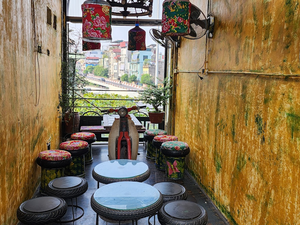

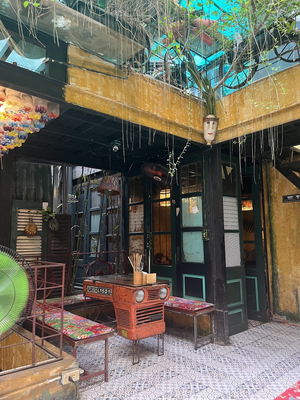

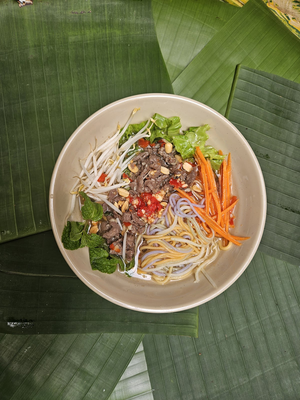

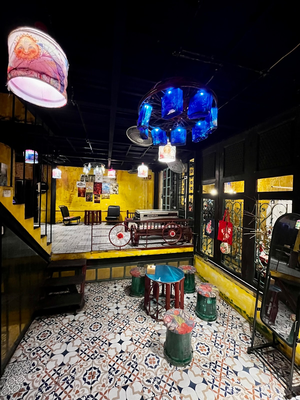

In [ ]:
for image_path in list(image_rate_dict.keys())[:4]:
    base_width = 300
    image = Image.open(image_path).convert('RGB')
    wpercent = (base_width / float(image.size[0]))
    hsize = int((float(image.size[1]) * float(wpercent)))
    image = image.resize((base_width, hsize), Image.Resampling.LANCZOS)
    display(image)

## 5. Good Camera Angle Detector

In [ ]:
def get_transform(train):
    transforms = []
    if train:
        transforms.append(T.RandomHorizontalFlip(0.5))
    transforms.append(T.ToDtype(torch.float, scale=True))
    transforms.append(T.ToPureTensor())
    return T.Compose(transforms)

def get_model(num_classes):
    # Load pre-trained Faster R-CNN model
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights="DEFAULT")

    # Modify the last fully connected layer of the classifier
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    # replace the pre-trained head with a new one
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    return model

In [ ]:
# train on the GPU or on the CPU, if a GPU is not available
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

# our dataset has two classes only - background and person
num_classes = 2

# get the model using our helper function
model = get_model(num_classes)
# model= nn.DataParallel(model)
# move model to the right device
model.to(device)

model.load_state_dict(torch.load("/content/good_image_detect_faster_rcnn.pth", map_location=torch.device('cpu')))

<All keys matched successfully>

In [ ]:
# @title Adjusting the Output Image to be in Square format
def adjust_to_square(bboxes, image_width, image_height):
    square_bboxes = []
    for bbox in bboxes.tolist():
        x, y, w, h = bbox
        width = w
        height = h
        side_length = min(width, height)

        # Center the box around the original center point
        center_x = x + (width / 2)
        center_y = y + (height / 2)
        new_x = center_x - (side_length / 2)
        new_y = center_y - (side_length / 2)
        # Ensure the bounding box remains within the image boundaries
        if new_x < 0:
            new_x = 0
        if new_y < 0:
            new_y = 0
        if new_x + side_length > image_width:
            new_x = image_width - side_length
        if new_y + side_length > image_height:
            new_y = image_height - side_length

        # Clip to image boundaries
        new_x = max(new_x, 0)
        new_y = max(new_y, 0)
        new_w = min(side_length, image_width - new_x)
        new_h = min(side_length, image_height - new_y)

#         if new_w != new_h:
#             new_side_length = min(new_w, new_h)

#             # Center the box around the original center point
#             new_center_x = x + (new_w / 2)
#             new_center_y = y + (new_h / 2)
#             new_x = new_center_x - (new_side_length / 2)
#             new_y = new_center_y - (new_side_length / 2)
#             # Ensure the bounding box remains within the image boundaries
#             if new_x < 0:
#                 new_x = 0
#             if new_y < 0:
#                 new_y = 0
#             if new_x + new_side_length > image_width:
#                 new_x = image_width - new_side_length
#             if new_y + new_side_length > image_height:
#                 new_y = image_height - new_side_length

#             # Clip to image boundaries
#             new_x = max(new_x, 0)
#             new_y = max(new_y, 0)
#             new_w = min(new_side_length, image_width - new_x)
#             new_h = min(new_side_length, image_height - new_y)
        square_bboxes.append([new_x, new_y, new_x + new_w, new_y + new_h])
    return square_bboxes

In [ ]:
import matplotlib.pyplot as plt
from torchvision.utils import draw_bounding_boxes, draw_segmentation_masks

pred_box_list = []

for image_path in list(image_rate_dict.keys())[:4]:
    image = read_image(image_path)
    height, width = (image.shape[1]), (image.shape[2])

    eval_transform = get_transform(train=False)

    model.eval()
    with torch.no_grad():
        x = eval_transform(image)
        # convert RGBA -> RGB and move to device
        x = x[:3, ...].to(device)
        predictions = model([x, ])
        pred = predictions[0]

    # image = (255.0 * (image - image.min()) / (image.max() - image.min())).to(torch.uint8)
    image = image[:3, ...]
    pred_labels = [f"Good image: {score:.3f}" for label, score in zip(pred["labels"], pred["scores"])]
    pred_boxes = adjust_to_square(pred["boxes"],width, height)
    pred_box_list.append(pred_boxes[0])

In [ ]:
os.mkdir("/content/Croped_Images")

In [ ]:
image_list = list(image_rate_dict.keys())[:4]

for i in range(len(image_list)):
    test_image = Image.open(image_list[i])

    x1, y1, x2, y2 = pred_box_list[i]
    crop_box = (x1, y1, x2, y2)

    cropped_image = test_image.crop(crop_box)
    cropped_image.save("/content/Croped_Images/" + str(i) + ".jpg")

## 6. Html2Image

In [ ]:
from selenium import webdriver
from PIL import Image
from io import BytesIO

# Instantiate options
options = Options()

options.add_argument("--window-size=668,668")
options.add_argument('--headless')
options.add_argument('--no-sandbox')
options.add_argument('--disable-dev-shm-usage')

driver = gs.UndetectedChrome(options=options)
driver.set_window_size(800,895)
driver.get('file://' + '/content/index.html')
sleep(5)
driver.save_screenshot('Checkpoint.png')
sleep(5)
# Save the screenshot
screenshot = driver.get_screenshot_as_png()
sleep(5)
driver.quit()

# Convert the screenshot to an image
image = Image.open(BytesIO(screenshot))
image.save('output.png')

# Display the image
image.show()

<IPython.core.display.Javascript object>

## 7. Upload Content to Tiktok